# 🦺 SafeSight: Deep Learning for Construction PPE Recognition
### MLAI 504 — Neural Networks and Deep Learning · Course project

| | |
|---|---|
| **Dataset** | Roboflow Universe — *Construction Site Safety*, version 27 |
| **Task** | Classify annotated image regions into four PPE classes |
| **Framework** | TensorFlow / Keras |

**Research question.** Can an ImageNet-pretrained MobileNetV2 recognize PPE regions, and especially *missing* PPE, more reliably than a dense network or a CNN trained from scratch?

**Result.** Yes. The fine-tuned MobileNetV2 reaches **0.914 accuracy**, **0.909 macro-F1** and **0.924 recall on the unsafe classes** on 269 held-out test crops.

> **Scope.** The model classifies image regions that are already annotated as Hardhat, NO-Hardhat, Safety Vest or NO-Safety Vest. It does not detect PPE in full images, does not link equipment to a specific worker, and should not be used to make safety-enforcement decisions on its own.

<a id="contents"></a>

### 📑 Contents

| | Section | Covers | Subsections |
|:-:|---|---|---|
| ⚙️ | [**Setup**](#setup) | Protocol, run mode, configuration | |
| 🗂️ | [**1. Dataset Selection**](#section-1) | Source, size, features and target variable |  |
| 🧹 | [**2. Data Preprocessing**](#section-2) | Cleaning, outliers, exploration, leakage, normalization | [2.1 Audit & cropping](#section-2-1) · [2.2 Exploration](#section-2-2) · [2.3 Leakage check](#section-2-3) · [2.4 Normalization & weights](#section-2-4) |
| 🧱 | [**3. Step-by-Step Model Creation**](#section-3) | From an MLP to regularized CNNs | [3.1 Utilities](#section-3-1) · [3.2 MLP](#section-3-2) · [3.3 CNN (ReLU)](#section-3-3) · [3.4 CNN (ELU)](#section-3-4) · [3.5 Summary](#section-3-5) |
| 🎛️ | [**4. Hyperparameter Tuning**](#section-4) | Random search over seven hyperparameters |  |
| 🔁 | [**5. Transfer Learning**](#section-5) | MobileNetV2, frozen and fine-tuned | [5.1 Frozen backbone](#section-5-1) · [5.2 Fine-tuning](#section-5-2) |
| 🎓 | [**6. Integration of Course Topics**](#section-6) | Where each course concept is used |  |
| 📊 | [**7. Evaluation and Interpretation**](#section-7) | Test metrics, curves, errors, challenges | [7.1 Model comparison](#section-7-1) · [7.2 Test results](#section-7-2) · [7.3 Learning curves](#section-7-3) · [7.4 Error analysis](#section-7-4) · [7.5 Challenges](#section-7-5) |
| ✅ | [**8. Conclusion**](#section-8) | Answer, gains per stage, limitations |  |
| 📚 | [**References**](#references) | Course lectures, dataset, papers | |

> **Pipeline at a glance:** dataset ➜ cleaning & cropping ➜ MLP ➜ CNN ➜ random search ➜ MobileNetV2 (frozen ➜ fine-tuned) ➜ one final test

Each stage is presented as **Rationale → Code → Observations**.

### ▶️ Running the notebook
1. Install the dependencies with `pip install -r requirements.txt` (Python 3.12), or open the notebook in Google Colab.
2. Make the dataset available as described in `data/README.md`.
3. Run all cells. By default (`RETRAIN = False`), the trained models are loaded from `models/checkpoints/` and evaluated, which takes about two minutes. Set `RETRAIN = True` to train every model from scratch: about 7 hours on a CPU, and far less on a GPU.

> **Note.** All models were trained once, on a CPU, for 6.8 hours in total. The observations in this notebook describe that training run.

<a id="setup"></a>

## ⚙️ Setup
<sub>[⬆ Back to contents](#contents)</sub>

**Experimental protocol**
- Use Roboflow's predefined train, validation and test partitions, which are split by image. Crops are cut *within* each partition, so no image contributes to more than one split.
- Make every modelling decision on the validation set. The final model is chosen by validation macro-F1, with unsafe-class recall as the tie-breaker.
- Evaluate on the test set **once**, at the very end.
- Stop if any partition is missing one of the four classes.

**Run mode.** The `RETRAIN` flag in the next cell controls training:
- `False` (default): each experiment loads its trained checkpoint from `models/checkpoints/` and is re-scored on the validation set.
- `True`: each model is trained from scratch and its checkpoint is overwritten.
- A model with no saved checkpoint is always trained.

The cells below install the dependencies, fix the random seed, create the output folders and save the configuration.

In [1]:
# Install once in Colab; restart runtime only if pip requests it.
%pip -q install "roboflow>=1.1,<3" "tensorflow>=2.16,<2.20" "scikit-learn>=1.4" "pandas>=2.0" "opencv-python-headless>=4.8" "seaborn>=0.13" "pyyaml>=6" "Pillow>=10"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, random, time, re, math, warnings, hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import yaml
from PIL import Image
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_recall_fscore_support, balanced_accuracy_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

# Reproducibility: one seed for Python, NumPy and TensorFlow
SEED = 504
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# Project folders
DATA_DIR = Path('data')                # dataset (see data/README.md)
MODELS = Path('models')                # final exported model
CKPT = MODELS / 'checkpoints'          # best checkpoint of every experiment
FIGS = Path('results/figures')         # plots
TABLES = Path('results/tables')        # CSV / JSON results
for folder in (CKPT, FIGS, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

# Run mode: False = load the trained checkpoints from models/checkpoints/ (a few minutes)
#           True  = train every model from scratch (about 7 h on CPU, much faster on a GPU)
RETRAIN = False

# Experiment configuration, saved so every run is documented
CONFIG = {'workspace': 'roboflow-universe-projects', 'project': 'construction-site-safety', 'version': 27,
          'image_size': 160,       # crop resolution fed to every model
          'crop_padding': 0.10,    # extra context around each box, as a fraction of box size
          'min_box_pixels': 12,    # outlier rule: drop crops smaller than this after clipping
          'batch_size': 32,
          'scratch_epochs': 15, 'search_epochs': 9, 'transfer_epochs': 15, 'fine_tune_epochs': 8}
(TABLES / 'configuration.json').write_text(json.dumps(CONFIG, indent=2))
print('TensorFlow:', tf.__version__, 'GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.19.1 GPUs: []


<a id="section-1"></a>

## 🗂️ 1. Dataset Selection
<sub>[⬆ Back to contents](#contents)</sub>

**Source.** [Construction Site Safety, version 27](https://universe.roboflow.com/roboflow-universe-projects/construction-site-safety/dataset/27) on Roboflow Universe, CC BY 4.0 licence.

**Why this dataset.** Missing hard hats and safety vests are among the most visible and preventable risks on construction sites. The dataset is public and labelled, and it includes explicit missing-PPE classes (`NO-Hardhat`, `NO-Safety Vest`), so the task has a direct safety meaning.

| Property | Value |
|---|---|
| Size | 2,799 images: 2,603 train / 114 validation / 82 test (Roboflow lists 2,801) |
| Origin | An augmented export of a 717-image source project, so the images are not all independent scenes |
| Features | RGB photos with YOLO bounding boxes `(class_id, cx, cy, width, height)`, normalized to [0, 1] |
| Source classes | 10: Hardhat, Mask, NO-Hardhat, NO-Mask, NO-Safety Vest, Person, Safety Cone, Safety Vest, machinery, vehicle |
| **Target variable** | 4 classes: **Hardhat, NO-Hardhat, Safety Vest, NO-Safety Vest** |
| Unit of analysis | One annotated box (a crop), not a whole image |

The next cell loads the dataset from `data/` or from the folder in `LOCAL_DATASET_DIR`, or downloads it with a Roboflow API key.

In [3]:
# Dataset location, in priority order:
#   1. LOCAL_DATASET_DIR environment variable
#   2. data/Construction-Site-Safety-27/ (already downloaded or extracted)
#   3. download from Roboflow with ROBOFLOW_API_KEY (environment variable or Colab secret)
LOCAL_DATASET_DIR = os.environ.get('LOCAL_DATASET_DIR', '').strip()
DEFAULT_DATA = DATA_DIR / f"Construction-Site-Safety-{CONFIG['version']}"
if LOCAL_DATASET_DIR:
    DATA = Path(LOCAL_DATASET_DIR).expanduser().resolve()
elif (DEFAULT_DATA / 'data.yaml').exists():
    DATA = DEFAULT_DATA.resolve()
else:
    key = os.environ.get('ROBOFLOW_API_KEY', '').strip()
    if not key:
        try:
            from google.colab import userdata
            key = userdata.get('ROBOFLOW_API_KEY') or ''
        except Exception:
            pass
    if not key:
        raise RuntimeError('Set ROBOFLOW_API_KEY (env/Colab secret), place the YOLOv8 export in '
                           f'{DEFAULT_DATA}, or set LOCAL_DATASET_DIR.')
    from roboflow import Roboflow
    rf = Roboflow(api_key=key)
    version = rf.workspace(CONFIG['workspace']).project(CONFIG['project']).version(CONFIG['version'])
    DATA = Path(version.download('yolov8', location=str(DEFAULT_DATA)).location).resolve()

assert DATA.exists(), f'Missing dataset folder: {DATA}'
YAML = next((p for p in [DATA / 'data.yaml', DATA / 'dataset.yaml'] if p.exists()), None)
assert YAML is not None, 'Expected data.yaml or dataset.yaml at export root'
meta = yaml.safe_load(YAML.read_text())

# data.yaml stores class names either as a list or as {id: name}
raw_names = meta['names']
names = {int(k): str(v) for k, v in raw_names.items()} if isinstance(raw_names, dict) else dict(enumerate(raw_names))
print('DATA:', DATA, 'classes:', names)

DATA: C:\Users\MohammedZaiter\source\repos\GitHub\Neural-Networks-and-Deep-Learning\data\Construction-Site-Safety-27 classes: {0: 'Hardhat', 1: 'Mask', 2: 'NO-Hardhat', 3: 'NO-Mask', 4: 'NO-Safety Vest', 5: 'Person', 6: 'Safety Cone', 7: 'Safety Vest', 8: 'machinery', 9: 'vehicle'}


**Observations.** The export contains all ten source classes. Only the four PPE classes are kept; boxes labelled `Person`, `Mask`, `NO-Mask`, `Safety Cone`, `machinery` and `vehicle` are ignored.

<a id="section-2"></a>

## 🧹 2. Data Preprocessing
<sub>[⬆ Back to contents](#contents)</sub>

<a id="section-2-1"></a>

### 2.1 Annotation audit, outlier rule and crop extraction

**Rationale.** Every YOLO box becomes one training example (a crop). Before cropping, each image and label row is checked:

| Problem | Handling |
|---|---|
| **Missing values:** unreadable image, missing label file, malformed or non-numeric row | Logged in an audit table and skipped. Never imputed, and never counted as a negative example |
| Invalid coordinates (non-finite, zero or negative size, centre outside the image) | Logged and skipped |
| **Outliers:** boxes smaller than 12 px after clipping | Removed by a fixed rule chosen before training, not tuned on results |

Each box is padded by 10% for context and clipped to the image borders. Every crop keeps the name of its parent image, so it can be traced back.

In [4]:
TARGET = ['Hardhat', 'NO-Hardhat', 'Safety Vest', 'NO-Safety Vest']

def canon(s):
    """Normalize a class name so that e.g. 'NO-Safety Vest' and 'no_safety_vest' match."""
    return re.sub(r'[^a-z0-9]', '', s.lower())

# Map the source classes onto the 4 target labels; all other classes are ignored
lookup = {canon(s): i for i, s in enumerate(TARGET)}
source_to_label = {i: lookup[canon(s)] for i, s in names.items() if canon(s) in lookup}
print('Source label mapping:', {names[i]: TARGET[j] for i, j in source_to_label.items()})
if set(source_to_label.values()) != set(range(4)):
    raise ValueError('Selected export does not contain all four target classes; inspect data.yaml or use another version.')

def folders(split):
    """Return the (images, labels) folders of a split; Roboflow may call validation 'valid' or 'val'."""
    opts = ['valid', 'val'] if split == 'valid' else [split]
    for k in opts:
        p = DATA / k / 'images'
        q = DATA / k / 'labels'
        if p.exists() and q.exists():
            return p, q
    raise FileNotFoundError(f'Missing {split} images/labels under {DATA}')

records = []      # one row per valid crop
audits = []       # one row per rejected image or annotation, with the reason
parent_sets = {}  # image IDs per split, for the leakage check
for split in ['train', 'valid', 'test']:
    image_dir, label_dir = folders(split)
    ids = set()
    images = sorted(p for p in image_dir.iterdir() if p.suffix.lower() in ('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
    for imgpath in images:
        ids.add(imgpath.stem)
        labelpath = label_dir / (imgpath.stem + '.txt')
        im = cv2.imread(str(imgpath))
        if im is None:
            audits.append((split, imgpath.name, 'unreadable image'))
            continue
        h, w = im.shape[:2]
        if not labelpath.exists():
            audits.append((split, imgpath.name, 'missing annotation'))
            continue
        for rownum, line in enumerate(labelpath.read_text().splitlines()):
            # Missing values / malformed rows are audited and skipped, never imputed
            tokens = line.split()
            if len(tokens) != 5:
                audits.append((split, imgpath.name, 'invalid label row'))
                continue
            try:
                cid = int(tokens[0])
                xc, yc, bw, bh = map(float, tokens[1:])
            except (ValueError, TypeError):
                audits.append((split, imgpath.name, 'non-numeric annotation'))
                continue
            if cid not in source_to_label:
                continue  # not one of the 4 target classes
            if not np.all(np.isfinite([xc, yc, bw, bh])) or bw <= 0 or bh <= 0 or not (0 <= xc <= 1 and 0 <= yc <= 1):
                audits.append((split, imgpath.name, 'invalid coordinates'))
                continue
            # Normalized YOLO box -> padded pixel coordinates, clipped to the image
            pad = CONFIG['crop_padding']
            x1 = int((xc - bw * (.5 + pad)) * w)
            x2 = int((xc + bw * (.5 + pad)) * w)
            y1 = int((yc - bh * (.5 + pad)) * h)
            y2 = int((yc + bh * (.5 + pad)) * h)
            x1, y1 = max(x1, 0), max(y1, 0)
            x2, y2 = min(x2, w), min(y2, h)
            # Outlier rule: boxes too small to show recognizable equipment
            if min(x2 - x1, y2 - y1) < CONFIG['min_box_pixels']:
                audits.append((split, imgpath.name, 'small clipped box'))
                continue
            records.append(dict(split=split, path=str(imgpath), parent=imgpath.name, annotation=rownum,
                                label=source_to_label[cid], x1=x1, y1=y1, x2=x2, y2=y2,
                                width=x2 - x1, height=y2 - y1, area=(x2 - x1) * (y2 - y1)))
    parent_sets[split] = ids

DF = pd.DataFrame(records)
AUD = pd.DataFrame(audits, columns=['split', 'image', 'reason'])

# Sanity checks before any modeling
assert not DF.empty, 'No eligible crops. Confirm dataset version and annotation classes.'
assert not (parent_sets['train'] & parent_sets['valid'] or parent_sets['train'] & parent_sets['test']
            or parent_sets['valid'] & parent_sets['test']), 'Same filename across image splits: investigate leakage.'
assert all(set(DF.loc[DF.split == s, 'label']) == set(range(4)) for s in ['train', 'valid', 'test']), \
    'A partition is missing a target category; investigate before proceeding.'

print('Region counts by split and class:')
display(pd.crosstab(DF.split, DF.label).rename(columns=dict(enumerate(TARGET))))
print('Audit totals:', AUD.reason.value_counts().to_dict())
# Saved manifest uses paths relative to the dataset folder (no machine-specific absolute paths)
DF.assign(path=DF.path.map(lambda p: Path(p).relative_to(DATA).as_posix())).to_csv(TABLES / 'crop_manifest.csv', index=False)
AUD.to_csv(TABLES / 'annotation_audit.csv', index=False)

Source label mapping: {'Hardhat': 'Hardhat', 'NO-Hardhat': 'NO-Hardhat', 'NO-Safety Vest': 'NO-Safety Vest', 'Safety Vest': 'Safety Vest'}
Region counts by split and class:


label,Hardhat,NO-Hardhat,Safety Vest,NO-Safety Vest
split,,,,
test,102,29,61,77
train,2803,2010,2797,3805
valid,73,52,38,92


Audit totals: {'small clipped box': 1451}


**Observations**
- **The annotations are clean.** There are no unreadable images, missing label files, malformed rows or invalid coordinates. The only rejections are **1,451 boxes** removed by the small-box rule.
- **11,939 crops in total:** 11,415 train, 255 validation and 269 test. All four classes appear in every split.
- **The training set is imbalanced.** NO-Safety Vest has 3,805 crops and NO-Hardhat 2,010, a ratio of about 1.9. Class weights (2.4) compensate for this.
- **The evaluation sets are small.** At an accuracy near 0.9, a 269-crop test set gives a 95% confidence interval of roughly ±3.6 percentage points. Crops from the same image are also correlated, so the true uncertainty is larger, and differences of a few points between models should not be over-interpreted.

<a id="section-2-2"></a>

### 2.2 Data exploration
**Rationale.** Look at the class balance in each split, the size of the crops (very small crops carry little information once resized to 160 × 160), and a few examples of each class.

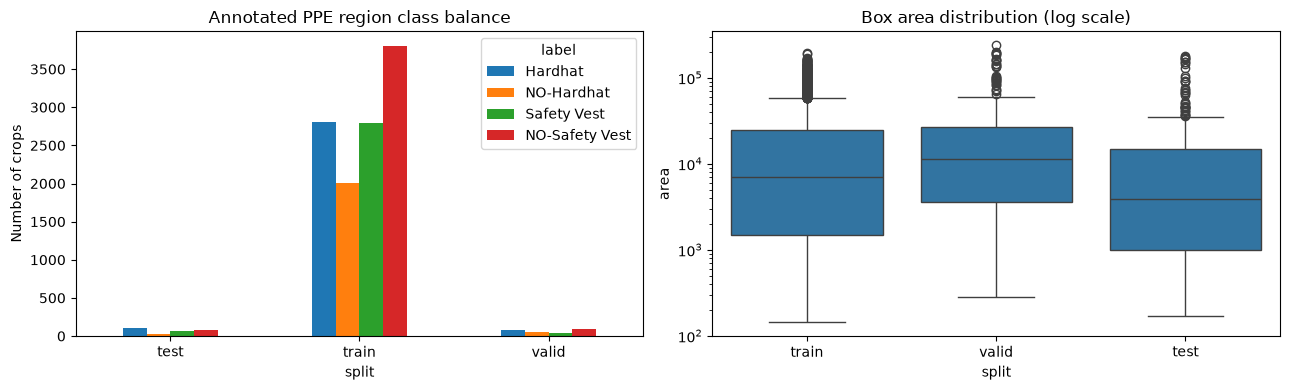

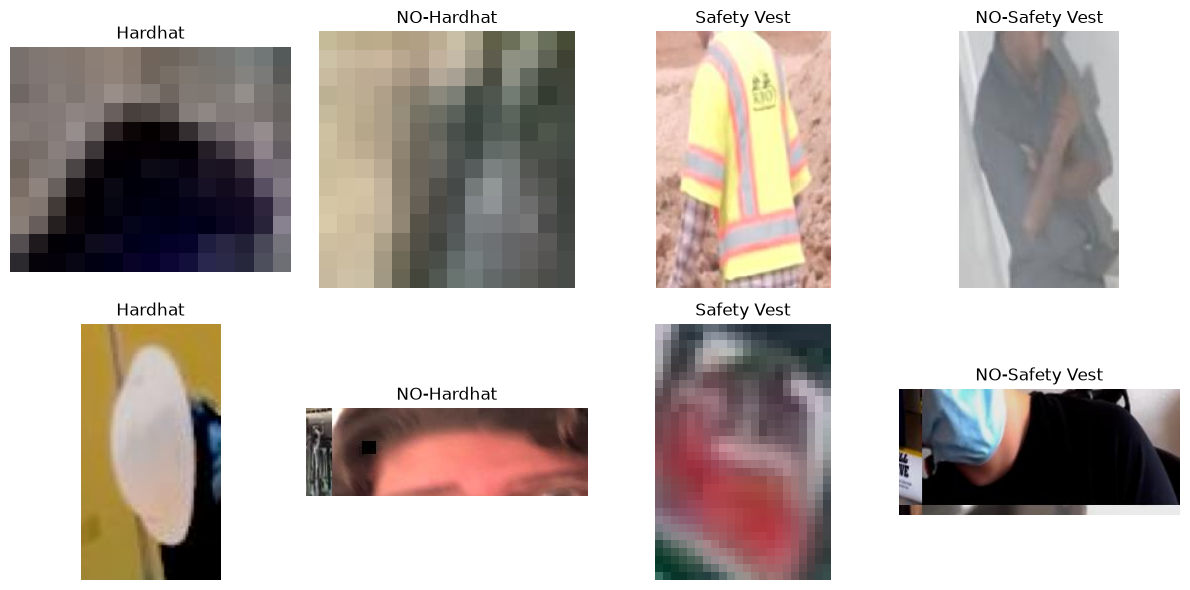

In [5]:
# Class balance per split, and crop size distribution (box area in pixels)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.crosstab(DF.split, DF.label).rename(columns=dict(enumerate(TARGET))).plot.bar(ax=axes[0], rot=0)
axes[0].set_title('Annotated PPE region class balance')
axes[0].set_ylabel('Number of crops')
sns.boxplot(data=DF, x='split', y='area', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Box area distribution (log scale)')
plt.tight_layout()
plt.savefig(FIGS / 'dataset_exploration.png', dpi=170)
plt.show()

# Two random training crops per class
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k in range(4):
    pool = DF[(DF.split == 'train') & (DF.label == k)]
    rows = pool.sample(n=min(2, len(pool)), random_state=SEED)
    for j, (_, r) in enumerate(rows.iterrows()):
        im = cv2.imread(r.path)
        crop = cv2.cvtColor(im[r.y1:r.y2, r.x1:r.x2], cv2.COLOR_BGR2RGB)
        axes[j, k].imshow(crop)
        axes[j, k].set_title(TARGET[k])
        axes[j, k].axis('off')
plt.tight_layout()
plt.savefig(FIGS / 'dataset_samples.png', dpi=170)
plt.show()

**Observations**
- About 96% of the crops are in the training set. The validation and test sets are small and roughly balanced, although the test set has only 29 NO-Hardhat crops.
- Box areas span three orders of magnitude, from about 150 px² to more than 100,000 px². The median is about 7,000 px² in training, 12,000 px² in validation and only 4,000 px² in **test**, so the test crops are smaller, and harder, than the crops used to select the model.
- Many crops are under about 1,000 px² (roughly 32 × 32 px) and must be enlarged to 160 × 160. This blurs the fine details that distinguish a hard hat from a yellow vest.

<a id="section-2-3"></a>

### 2.3 Duplicate and leakage check
**Rationale.** Augmented exports can contain identical images under different file names, so the SHA-256 hash of every parent image is compared across splits. Crops are deliberately **not** reshuffled into new splits after extraction, because that would put near-identical regions of the same image into both training and test.

In [6]:
# Exact-duplicate check: SHA-256 of every parent image, compared across splits
hashes = {}
for sp in ('train', 'valid', 'test'):
    paths = DF[DF.split == sp].path.drop_duplicates().tolist()
    hashes[sp] = {hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in paths}
for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]:
    overlap = hashes[a] & hashes[b]
    print(f'{a}/{b} exact-image hash overlaps: {len(overlap)}')
    if overlap:
        raise RuntimeError('Cross-split exact duplicates detected: fix dataset export before fitting models.')
print('Note: augmented/near-duplicate detection also requires perceptual review beyond SHA256.')

train/valid exact-image hash overlaps: 0
train/test exact-image hash overlaps: 0
valid/test exact-image hash overlaps: 0
Note: augmented/near-duplicate detection also requires perceptual review beyond SHA256.


**Observations.** No exact duplicates exist across splits. Hashing cannot detect near-duplicates, such as an augmented copy of a training scene, so this remains a threat to validity (see 7.5).

<a id="section-2-4"></a>

### 2.4 Splits, normalization, augmentation and class weights
**Rationale**
- **Splits.** The predefined Roboflow partitions are used as they are: training data fits the weights, validation guides every modelling decision, and test is used once at the end.
- **Normalization.** Crops are converted from BGR to RGB, resized to 160 × 160 and scaled to **[0, 1]**. MobileNetV2 expects **[-1, 1]**, so its model adds a `2x − 1` rescaling layer (section 5).
- **Augmentation.** Random horizontal flips, rotations of up to ±7% of a full turn (about ±25°) and contrast changes of up to ±12%, applied **only during training** as model layers. Grayscale and aggressive cropping are avoided because colour and shape are the main cues.
- **Class weights.** Inverse class frequency, so that errors on rarer classes cost more in the loss.

In [7]:
S = CONFIG['image_size']
B = CONFIG['batch_size']

def load_region(p, x1, y1, x2, y2):
    """Read one image, cut out the box, convert BGR -> RGB, resize to S x S and scale pixels to [0, 1]."""
    image = cv2.imread(p.decode('utf-8'))
    if image is None:
        raise OSError(p)
    crop = image[int(y1):int(y2), int(x1):int(x2)]
    crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    return cv2.resize(crop, (S, S), interpolation=cv2.INTER_AREA).astype('float32') / 255.

def tf_region(p, x1, y1, x2, y2, label):
    image = tf.numpy_function(load_region, [p, x1, y1, x2, y2], tf.float32)
    image.set_shape((S, S, 3))
    return image, tf.cast(label, tf.int32)

def make_ds(split, shuffle=False, batch=B):
    """tf.data pipeline that loads crops lazily from the manifest; only training data is shuffled."""
    d = DF[DF.split == split].reset_index(drop=True)
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.x1.values, d.y1.values,
                                             d.x2.values, d.y2.values, d.label.values))
    if shuffle:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(tf_region, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds('train', True)
val_ds = make_ds('valid')
test_ds = make_ds('test')

# Class weights: inverse frequency, so rarer classes count more in the loss
class_counts = np.bincount(DF.loc[DF.split == 'train', 'label'], minlength=4)
class_weight = {i: float(len(DF[DF.split == 'train']) / (4 * max(n, 1))) for i, n in enumerate(class_counts)}
print('Training class weights:', class_weight)

Training class weights: {0: 1.018105601141634, 1: 1.419776119402985, 2: 1.0202895959957097, 3: 0.75}


**Observations.** NO-Hardhat, the rarest class, receives a weight of 1.42, and NO-Safety Vest, the most common, receives 0.75. During training, a missed NO-Hardhat crop therefore costs almost twice as much as a missed NO-Safety Vest crop.

<a id="section-3"></a>

## 🧱 3. Step-by-Step Model Creation
<sub>[⬆ Back to contents](#contents)</sub>

**Rationale.** The models start from the simplest network and add structure step by step:

| Step | Model | What changes | Why |
|---|---|---|---|
| 1 | MLP (3.2) | Dense layers on flattened pixels | Baseline: a perceptron-style network with no notion of spatial layout (Lectures 02–03) |
| 2 | CNN with ReLU (3.3) | Convolutions, pooling and batch normalization | Local filters with shared weights should pick up helmet edges and vest textures (Lecture 06) |
| 3 | CNN with ELU and stronger regularization (3.4) | Activation, dropout, L2 and learning rate | Tests whether another activation and more regularization generalize better. Because four settings change at once, their individual effects cannot be separated |

All models use **sparse categorical cross-entropy** with integer labels (Lecture 04), a softmax output, class weights and the same validation set.

<a id="section-3-1"></a>

### 3.1 Shared training utilities
- `aug()`: the training-only augmentation block described in 2.4.
- `compile_model()`: compiles a model with **Adam** or **SGD with momentum 0.9**.
- `callbacks()`: **early stopping** (patience of 4 epochs on validation loss, best weights restored), **ReduceLROnPlateau** (halves the learning rate after 2 epochs without improvement) and a checkpoint of the best epoch.
- `scores()`: accuracy, **macro-F1** (every class weighs equally), **balanced accuracy** and **unsafe recall**, the mean recall of NO-Hardhat and NO-Safety Vest. Unsafe recall matters most, because a missed violation is the costliest error.
- `run()`: trains one experiment, or **loads its saved checkpoint** when `RETRAIN = False`, then logs its validation metrics and training history to `results/tables/`.

In [8]:
def aug():
    """Training-time augmentation; Keras disables these layers automatically at inference."""
    return keras.Sequential([layers.RandomFlip('horizontal'),
                             layers.RandomRotation(.07),
                             layers.RandomContrast(.12)], name='train_augmentation')

def compile_model(model, lr=1e-3, optimizer='adam'):
    if optimizer == 'adam':
        opt = keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = keras.optimizers.SGD(learning_rate=lr, momentum=.9)
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def callbacks(name):
    return [
        # stop when validation loss has not improved for 4 epochs, keep the best weights
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        # halve the learning rate when validation loss plateaus for 2 epochs
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=2, min_lr=1e-6),
        # save the best checkpoint of this experiment
        keras.callbacks.ModelCheckpoint(str(CKPT / f'{name}.keras'), monitor='val_loss', save_best_only=True),
    ]

def scores(model, ds, sp='valid'):
    """Accuracy, macro-F1, balanced accuracy and mean recall of the unsafe classes (NO-Hardhat, NO-Safety Vest)."""
    y = DF[DF.split == sp].label.to_numpy()
    p = model.predict(ds, verbose=0)
    pred = p.argmax(axis=1)
    return dict(accuracy=float(np.mean(pred == y)),
                macro_f1=float(f1_score(y, pred, average='macro', zero_division=0)),
                balanced_accuracy=float(balanced_accuracy_score(y, pred)),
                unsafe_recall=float(np.mean([np.mean(pred[y == i] == i) if (y == i).sum() else np.nan for i in [1, 3]])))

results = []     # one row of validation metrics per experiment
histories = {}   # Keras training history per experiment

# Results of the training run, reused when a model is loaded instead of retrained
SAVED_TIMES = (pd.read_csv(TABLES / 'validation_results.csv').set_index('model')['training_seconds'].to_dict()
               if (TABLES / 'validation_results.csv').exists() else {})
SAVED_HISTORIES = (json.loads((TABLES / 'training_histories.json').read_text())
                   if (TABLES / 'training_histories.json').exists() else {})

def run(name, model, lr, epochs, train=train_ds, validation=val_ds, optimizer='adam'):
    """Train one experiment (or load its checkpoint when RETRAIN is False), score it on validation and log the results."""
    ckpt = CKPT / f'{name}.keras'
    if not RETRAIN and ckpt.exists():
        # Reuse the trained model instead of training it again
        model = keras.models.load_model(ckpt)
        print(f'{name}: loaded trained model from {ckpt.as_posix()}')
        metrics = scores(model, validation, 'valid')
        seconds = SAVED_TIMES.get(name, float('nan'))
        if name in SAVED_HISTORIES:
            histories[name] = SAVED_HISTORIES[name]
    else:
        compile_model(model, lr, optimizer)
        t = time.time()
        h = model.fit(train, validation_data=validation, epochs=epochs, callbacks=callbacks(name),
                      class_weight=class_weight, verbose=2)
        metrics = scores(model, validation, 'valid')
        seconds = round(time.time() - t, 2)
        histories[name] = {m: [float(v) for v in vals] for m, vals in h.history.items()}
        (TABLES / 'training_histories.json').write_text(json.dumps(histories, indent=1))
    row = {'model': name, 'training_seconds': seconds, **metrics}
    results.append(row)
    pd.DataFrame(results).to_csv(TABLES / 'validation_results.csv', index=False)
    print(name, row)
    return model

<a id="section-3-2"></a>

### 3.2 Step 1 — Baseline MLP
**Rationale.** A multilayer perceptron is the simplest neural network that can learn a non-linear decision boundary. Crops are reduced to 64 × 64 before flattening: at the full 160 × 160 resolution, the first dense layer alone would need about 9.8 million weights, compared with about 1.6 million at 64 × 64.

**Architecture:** Resizing(64 × 64) → Flatten (12,288 inputs) → Dense(128, ReLU) → Dropout(0.35) → Dense(4, softmax). Adam optimizer, learning rate 1e-3.

In [9]:
def make_mlp():
    i = keras.Input((S, S, 3))
    x = layers.Resizing(64, 64)(i)          # 64 x 64 x 3 = 12,288 inputs keeps the dense layer manageable
    x = layers.Flatten()(x)                 # spatial structure is discarded here
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(.35)(x)
    return keras.Model(i, layers.Dense(4, activation='softmax')(x), name='baseline_mlp')

mlp = run('01_mlp', make_mlp(), 1e-3, CONFIG['scratch_epochs'])

01_mlp: loaded trained model from models/checkpoints/01_mlp.keras
01_mlp {'model': '01_mlp', 'training_seconds': 459.95, 'accuracy': 0.5725490196078431, 'macro_f1': 0.5678498098474734, 'balanced_accuracy': 0.5916126031737611, 'unsafe_recall': 0.5739966555183946}


**Observations**
- Validation **accuracy 0.573, macro-F1 0.568**, unsafe recall 0.574: clearly better than chance (0.25), but weak.
- Early stopping ended training at epoch 14; the best validation loss (1.049) came at epoch 10.
- Training accuracy only reached about 0.51, so the MLP **under-fits**. Once the pixels are flattened, it cannot use the shape of a helmet or the stripes on a vest.
- It is the fastest model (about 8 minutes on a CPU), which makes it a useful lower bound.

<a id="section-3-3"></a>

### 3.3 Step 2 — CNN with ReLU
**Rationale.** Convolutions share weights across positions and learn local patterns, which suits small objects with distinctive shapes and colours.

**Architecture:** three blocks of Conv(3 × 3) → **BatchNorm** → **ReLU** → MaxPool with 24, 48 and 96 filters, followed by GlobalAveragePooling → Dropout(0.3) → Dense(4, softmax). L2 regularization of 1e-4 on the convolution weights, plus training augmentation. Adam optimizer, learning rate 1e-3.

In [10]:
def make_cnn(activation='relu', filters=24, dropout=.3, l2=1e-4, augmentation=True):
    i = keras.Input((S, S, 3))
    x = aug()(i) if augmentation else i
    # three Conv -> BatchNorm -> activation -> MaxPool blocks, doubling the filters each time
    for mult in (1, 2, 4):
        x = layers.Conv2D(filters * mult, 3, padding='same', kernel_regularizer=regularizers.l2(l2))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return keras.Model(i, layers.Dense(4, activation='softmax')(x), name=f'cnn_{activation}_{filters}')

cnn = run('02_cnn_relu', make_cnn(), 1e-3, CONFIG['scratch_epochs'])

02_cnn_relu: loaded trained model from models/checkpoints/02_cnn_relu.keras
02_cnn_relu {'model': '02_cnn_relu', 'training_seconds': 3314.14, 'accuracy': 0.7019607843137254, 'macro_f1': 0.6958048836733768, 'balanced_accuracy': 0.7102631820077981, 'unsafe_recall': 0.7775919732441472}


**Observations**
- Validation **accuracy 0.702, macro-F1 0.696** (0.128 higher than the MLP), unsafe recall 0.778. Spatial structure clearly matters for this task.
- Early stopping ended training at epoch 13; the best validation loss (0.786) came at epoch 9.
- Validation accuracy fluctuates from epoch to epoch, for example from 0.51 to 0.69 between epochs 5 and 6. With only 255 validation crops, small weight changes flip many predictions.
- Training accuracy (about 0.68) is *lower* than validation accuracy because dropout and augmentation are active during training. There is no sign of over-fitting yet.

<a id="section-3-4"></a>

### 3.4 Step 3 — CNN with ELU and stronger regularization
**Rationale.** ELU outputs small negative values instead of zero, which avoids "dead" ReLU units and keeps mean activations closer to zero. At the same time, regularization is strengthened (dropout 0.3 → 0.45, L2 1e-4 → 5e-4) and the learning rate is halved (5e-4), to test whether a more constrained model generalizes better.

In [11]:
# Same architecture as step 2: ELU activation, stronger dropout and L2, half the learning rate
elu = run('03_cnn_elu_dropout', make_cnn(activation='elu', dropout=.45, l2=5e-4), 5e-4, CONFIG['scratch_epochs'])

03_cnn_elu_dropout: loaded trained model from models/checkpoints/03_cnn_elu_dropout.keras
03_cnn_elu_dropout {'model': '03_cnn_elu_dropout', 'training_seconds': 3932.93, 'accuracy': 0.6941176470588235, 'macro_f1': 0.6893775626192507, 'balanced_accuracy': 0.7087782695502673, 'unsafe_recall': 0.6918896321070234}


**Observations**
- Validation **accuracy 0.694, macro-F1 0.689**: practically a tie with the ReLU CNN (a difference of 0.007, well within the noise discussed in 2.1). Unsafe recall fell to 0.692.
- The model used all 15 epochs without stopping early, and its validation loss was still falling (0.865 at epoch 14). It is **under-trained, not over-fitted**: stronger regularization and a lower learning rate slow learning down, so any benefit would need more epochs to appear.

<a id="section-3-5"></a>

### 3.5 Summary of the progression

| Step | Model | Val. accuracy | Val. macro-F1 | Unsafe recall |
|---|---|---:|---:|---:|
| 1 | MLP | 0.573 | 0.568 | 0.574 |
| 2 | CNN (ReLU) | **0.702** | **0.696** | **0.778** |
| 3 | CNN (ELU + dropout + L2) | 0.694 | 0.689 | 0.692 |

Moving from dense layers to convolutions brought the largest gain. Within a 15-epoch budget, changing the activation and regularization made no measurable difference.

<a id="section-4"></a>

## 🎛️ 4. Hyperparameter Tuning
<sub>[⬆ Back to contents](#contents)</sub>

**Rationale.** **Random search** samples all hyperparameters jointly and, for the same budget, tries more distinct values of each one than a grid search does (Bergstra & Bengio, 2012). Each trial trains the CNN from 3.3 and is scored **on the validation set only**.

| Hyperparameter | Values searched |
|---|---|
| Activation | ReLU, ELU, tanh |
| Base filters | 16, 24, 32 |
| Dropout | 0.2, 0.35, 0.5 |
| L2 | 1e-5, 1e-4, 5e-4 |
| Learning rate | 1e-4, 3e-4, 1e-3 |
| Batch size | 16, 32 |
| Optimizer | Adam, SGD (momentum 0.9) |
| Epochs | Fixed at 9, with early stopping |

Only six trials fitted within the CPU budget, so the search gives a rough picture rather than a precise optimum.

In [12]:
# Draw 6 random configurations from the search space (seeded, so the draw is reproducible)
rng = np.random.default_rng(SEED)
space = [dict(activation=str(rng.choice(['relu', 'elu', 'tanh'])),
              filters=int(rng.choice([16, 24, 32])),
              dropout=float(rng.choice([.2, .35, .5])),
              l2=float(rng.choice([1e-5, 1e-4, 5e-4])),
              lr=float(rng.choice([1e-4, 3e-4, 1e-3])),
              batch=int(rng.choice([16, 32])),
              optimizer=str(rng.choice(['adam', 'sgd'])))
         for _ in range(6)]

search_rows = []
for idx, hp in enumerate(space):
    tf.keras.utils.set_random_seed(SEED + idx)
    m = make_cnn(hp['activation'], hp['filters'], hp['dropout'], hp['l2'])
    tr = make_ds('train', True, hp['batch'])
    va = make_ds('valid', False, hp['batch'])
    model_name = f'04_search_{idx + 1:02}'
    m = run(model_name, m, hp['lr'], CONFIG['search_epochs'], tr, va, hp['optimizer'])
    search_rows.append({'name': model_name, **hp, **scores(m, va, 'valid')})
    keras.backend.clear_session()

SEARCH = pd.DataFrame(search_rows).sort_values('macro_f1', ascending=False)
SEARCH.to_csv(TABLES / 'hyperparameter_search.csv', index=False)
display(SEARCH)
BEST_NAME = SEARCH.iloc[0]['name']
print('Top scratch-CNN trial:', BEST_NAME)

04_search_01: loaded trained model from models/checkpoints/04_search_01.keras
04_search_01 {'model': '04_search_01', 'training_seconds': 1423.84, 'accuracy': 0.592156862745098, 'macro_f1': 0.576895378341998, 'balanced_accuracy': 0.5904414619266818, 'unsafe_recall': 0.6538461538461539}

04_search_02: loaded trained model from models/checkpoints/04_search_02.keras
04_search_02 {'model': '04_search_02', 'training_seconds': 3110.09, 'accuracy': 0.5803921568627451, 'macro_f1': 0.582459512298222, 'balanced_accuracy': 0.6170877510471097, 'unsafe_recall': 0.5238294314381271}
04_search_03: loaded trained model from models/checkpoints/04_search_03.keras
04_search_03 {'model': '04_search_03', 'training_seconds': 3536.85, 'accuracy': 0.5882352941176471, 'macro_f1': 0.5884292080354567, 'balanced_accuracy': 0.6083963488002546, 'unsafe_recall': 0.6070234113712374}
04_search_04: loaded trained model from models/checkpoints/04_search_04.keras
04_search_04 {'model': '04_search_04', 'training_seconds': 1

,name,activation,filters,dropout,l2,lr,batch,optimizer,accuracy,macro_f1,balanced_accuracy,unsafe_recall
5,04_search_06,elu,16,0.50,0.00001,0.0003,32,adam,0.631373,0.628644,0.642882,0.627508
4,04_search_05,relu,16,0.35,0.00050,0.0010,32,sgd,0.588235,0.591542,0.624737,0.667642
2,04_search_03,elu,32,0.50,0.00050,0.0003,32,sgd,0.588235,0.588429,0.608396,0.607023
1,04_search_02,tanh,32,0.50,0.00010,0.0010,32,sgd,0.580392,0.582460,0.617088,0.523829
0,04_search_01,tanh,16,0.20,0.00001,0.0003,32,adam,0.592157,0.576895,0.590441,0.653846
3,04_search_04,tanh,16,0.35,0.00050,0.0003,32,sgd,0.556863,0.545701,0.568302,0.473662


Top scratch-CNN trial: 04_search_06


**Observations**
- **Best trial:** `04_search_06` (ELU, 16 filters, dropout 0.5, L2 1e-5, learning rate 3e-4, Adam), with **macro-F1 0.629**.
- **The search did not beat the hand-designed CNN** (0.696), for four reasons:
  1. **Too few epochs.** Each trial had 9 epochs instead of 15, and most were still improving when they stopped; trials 03 and 05 reached their lowest validation loss in the final epoch. The search therefore compared under-trained models.
  2. **Too few trials.** Six trials cover less than 1% of the 972 possible combinations.
  3. **Batch size was never tested.** All six random draws picked 32, so its effect remains unknown.
  4. **Noise.** Differences of 0.01–0.04 macro-F1 between trials are within the variance of a 255-crop validation set.
- **One clear pattern:** the three **tanh** trials rank last (4th to 6th), which is consistent with saturating activations slowing gradient flow compared with ReLU and ELU. Neither Adam nor SGD wins consistently.
- **Next steps on a GPU:** include the number of epochs in the search (or use a larger budget with early stopping), test both batch sizes explicitly (for example with a grid over learning rate × batch size), and run more trials or use Keras Tuner / Hyperband.

<a id="section-5"></a>

## 🔁 5. Transfer Learning — MobileNetV2
<sub>[⬆ Back to contents](#contents)</sub>

**Rationale.** With about 11,000 crops, a network trained from scratch must learn low-level features such as edges, colours and textures from very little data. A backbone pretrained on ImageNet (1.28 million images) has already learned them (Lecture 05).

**Why MobileNetV2.** The specification gives VGG16, ResNet and Inception as examples. MobileNetV2 (Sandler et al., 2018) has about 2.3 million backbone parameters, compared with about 138 million for VGG16 and 25.6 million for ResNet50, which made two-stage fine-tuning feasible on a CPU. ImageNet weights are available for 160 × 160 inputs, and its inverted-residual blocks with depthwise-separable convolutions are an example of the advanced architectures covered in the course.

**Plan**
- **Stage A, feature extraction:** freeze the entire backbone and train only a new head, GlobalAveragePooling → Dense(128, ReLU) → Dropout(0.4) → Dense(4, softmax), with a learning rate of 1e-3.
- **Stage B, fine-tuning:** unfreeze the **last 30 backbone layers** while keeping their **BatchNorm layers frozen**, and continue at a **10× lower learning rate** (1e-4). The model is recompiled after the trainable flags change.

<a id="section-5-1"></a>

### 5.1 Stage A — frozen backbone

In [13]:
def build_transfer():
    inp = keras.Input(shape=(S, S, 3))
    x = aug()(inp)
    x = layers.Rescaling(2., offset=-1.)(x)   # [0, 1] -> [-1, 1], the input range MobileNetV2 was trained on
    backbone = keras.applications.MobileNetV2(input_shape=(S, S, 3), include_top=False, weights='imagenet')
    backbone.trainable = False                # Stage A: pretrained features stay fixed
    x = backbone(x, training=False)           # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(.4)(x)
    return keras.Model(inp, layers.Dense(4, activation='softmax')(x), name='mobilenetv2_ppe'), backbone

transfer, backbone = build_transfer()
transfer = run('05_transfer_frozen', transfer, 1e-3, CONFIG['transfer_epochs'])

05_transfer_frozen: loaded trained model from models/checkpoints/05_transfer_frozen.keras
05_transfer_frozen {'model': '05_transfer_frozen', 'training_seconds': 1573.05, 'accuracy': 0.8549019607843137, 'macro_f1': 0.8486611317496784, 'balanced_accuracy': 0.8591512383262643, 'unsafe_recall': 0.8457357859531773}


**Observations**
- After a **single epoch**, validation accuracy is already 0.765, higher than the best epoch of any model trained from scratch (0.737). ImageNet features transfer well to PPE crops.
- Final validation **accuracy 0.855, macro-F1 0.849**, unsafe recall 0.846: 0.15 macro-F1 above the best scratch CNN.
- Early stopping ended training at epoch 10; the best validation loss (0.515) came at epoch 6. Training and validation accuracy are almost equal (about 0.86 each), so the frozen model is not over-fitting.

<a id="section-5-2"></a>

### 5.2 Stage B — fine-tuning the top of the backbone
**Rationale.** The last layers of a pretrained network hold the most task-specific features, so they are the ones worth adapting. **BatchNorm stays frozen** because noisy statistics from small batches would overwrite its ImageNet statistics. A **low learning rate** (1e-4) adjusts the pretrained weights gradually instead of destroying them.

In [14]:
# Stage B: unfreeze only the last 30 backbone layers, but keep their BatchNorm layers frozen
backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False
for layer in backbone.layers[-30:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# run() recompiles the model (required after changing trainable flags) with a 10x lower learning rate
transfer = run('06_transfer_finetuned', transfer, 1e-4, CONFIG['fine_tune_epochs'])
print('Trainable parameters:', sum(np.prod(v.shape) for v in transfer.trainable_weights))

06_transfer_finetuned: loaded trained model from models/checkpoints/06_transfer_finetuned.keras
06_transfer_finetuned {'model': '06_transfer_finetuned', 'training_seconds': 1431.23, 'accuracy': 0.8980392156862745, 'macro_f1': 0.8960605282707708, 'balanced_accuracy': 0.8998822679780957, 'unsafe_recall': 0.907190635451505}
Trainable parameters: 1675204


**Observations**
- Final validation **accuracy 0.898, macro-F1 0.896**, unsafe recall 0.907: another 0.047 macro-F1 over the frozen model, with 1.68 million trainable parameters.
- **Fine-tuning was unstable.** At epoch 4, the validation loss jumped to 0.908 and validation accuracy fell to 0.765. ReduceLROnPlateau halved the learning rate to 5e-5, and epoch 5 gave the best result (validation loss 0.409, accuracy 0.898).
- **The model over-fitted after epoch 5.** Training accuracy kept rising to 0.95 while validation accuracy dropped to 0.86. Early stopping and checkpointing kept the epoch-5 weights.
- **Lesson:** fine-tuning pays off only with a low learning rate, an adaptive schedule and checkpointing. With a fixed learning rate and no checkpoint, the final model would have been worse.

<a id="section-6"></a>

## 🎓 6. Integration of Course Topics
<sub>[⬆ Back to contents](#contents)</sub>

| Topic | Where it is used | Section |
|---|---|---|
| Perceptron and MLP (Lectures 02–03) | Baseline dense network | 3.2 |
| Activation functions | ReLU (3.3), ELU (3.4), tanh (search), softmax output (all models) | 3–5 |
| Loss functions (Lecture 04) | Sparse categorical cross-entropy, weighted by class to handle imbalance | 2.4, 3.1 |
| Optimization algorithms (Lecture 04) | Adam, SGD with momentum 0.9, learning-rate reduction on plateau | 3.1, 4 |
| Regularization | Dropout, L2 weight decay, data augmentation, early stopping | 3.3–3.4, 4, 5 |
| Normalization | Pixel scaling to [0, 1] and [-1, 1]; batch normalization in every convolution block | 2.4, 3.3 |
| CNN architecture (Lecture 06) | Convolution, max-pooling, global average pooling | 3.3 |
| Advanced architectures | MobileNetV2: depthwise-separable convolutions, inverted residuals | 5 |
| Transfer learning (Lecture 05) | Frozen feature extraction, partial unfreezing, lower fine-tuning learning rate | 5 |
| Hyperparameter tuning | Seeded random search over seven hyperparameters | 4 |
| Evaluation metrics | Macro-F1, balanced accuracy, per-class precision and recall, confusion matrix | 7 |

**Not applied**
- **Recurrent networks (Lecture 07)** model sequences; these images are independent and have no temporal order.
- **Alternative losses** such as focal loss, and the **LeakyReLU** activation, were not tested; class weighting handles the imbalance instead. Both would be reasonable extensions.

<a id="section-7"></a>

## 📊 7. Evaluation and Interpretation
<sub>[⬆ Back to contents](#contents)</sub>

**Protocol.** The model is chosen by **validation macro-F1**, with unsafe recall as the tie-breaker, and its best checkpoint is evaluated **once** on the held-out test set. Here, "unsafe recall" is the recall of the NO-Hardhat and NO-Safety Vest regions, not of violations per worker. Because accuracy alone can hide rare but costly misses, per-class metrics are reported as well.

<a id="section-7-1"></a>

### 7.1 Comparison of all models (validation)

In [15]:
# All experiments ranked by validation macro-F1 (tie-break: unsafe-class recall)
VAL = pd.DataFrame(results).sort_values(['macro_f1', 'unsafe_recall'], ascending=False)
display(VAL)

,model,training_seconds,accuracy,macro_f1,balanced_accuracy,unsafe_recall
10,06_transfer_finetuned,1431.23,0.898039,0.896061,0.899882,0.907191
9,05_transfer_frozen,1573.05,0.854902,0.848661,0.859151,0.845736
1,02_cnn_relu,3314.14,0.701961,0.695805,0.710263,0.777592
2,03_cnn_elu_dropout,3932.93,0.694118,0.689378,0.708778,0.691890
8,04_search_06,1786.35,0.631373,0.628644,0.642882,0.627508
7,04_search_05,2075.12,0.588235,0.591542,0.624737,0.667642
5,04_search_03,3536.85,0.588235,0.588429,0.608396,0.607023
4,04_search_02,3110.09,0.580392,0.582460,0.617088,0.523829
3,04_search_01,1423.84,0.592157,0.576895,0.590441,0.653846
0,01_mlp,459.95,0.572549,0.567850,0.591613,0.573997


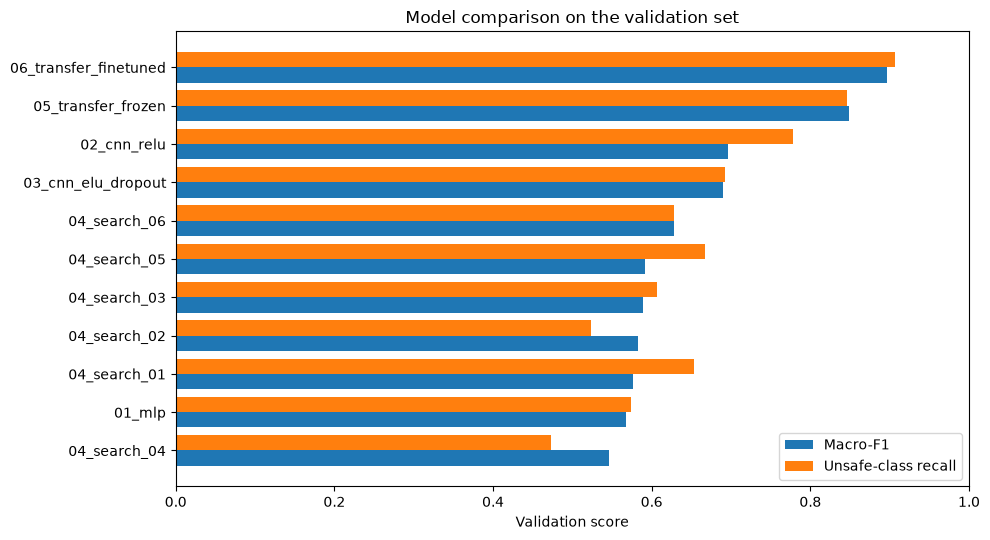

In [16]:
# Model comparison chart: validation macro-F1 and unsafe-class recall for every experiment
order = VAL.sort_values('macro_f1')
ypos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(ypos - 0.2, order['macro_f1'], height=0.4, label='Macro-F1')
ax.barh(ypos + 0.2, order['unsafe_recall'], height=0.4, label='Unsafe-class recall')
ax.set_yticks(ypos, order['model'])
ax.set_xlim(0, 1)
ax.set_xlabel('Validation score')
ax.set_title('Model comparison on the validation set')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIGS / 'model_comparison.png', dpi=170)
plt.show()

**Observations.** The models fall into clear tiers: **transfer learning** (0.85–0.90 macro-F1) is far ahead of the **CNNs trained from scratch** (0.55–0.70) and the **MLP** (0.57). The fine-tuned MobileNetV2 ranks first on every metric and is the model taken forward to the test.

<a id="section-7-2"></a>

### 7.2 Final held-out test

{
  "chosen_model": "06_transfer_finetuned",
  "test_accuracy": 0.9144981412639405,
  "test_macro_f1": 0.9090691050906964,
  "test_balanced_accuracy": 0.920411504444524,
  "test_unsafe_recall": 0.9243170622480967,
  "number_test_crops": 269
}


,precision,recall,f1-score,support
Hardhat,0.922,0.931,0.927,102.000
NO-Hardhat,0.824,0.966,0.889,29.000
Safety Vest,0.902,0.902,0.902,61.000
NO-Safety Vest,0.958,0.883,0.919,77.000
accuracy,0.914,0.914,0.914,0.914
macro avg,0.901,0.920,0.909,269.000
weighted avg,0.917,0.914,0.915,269.000


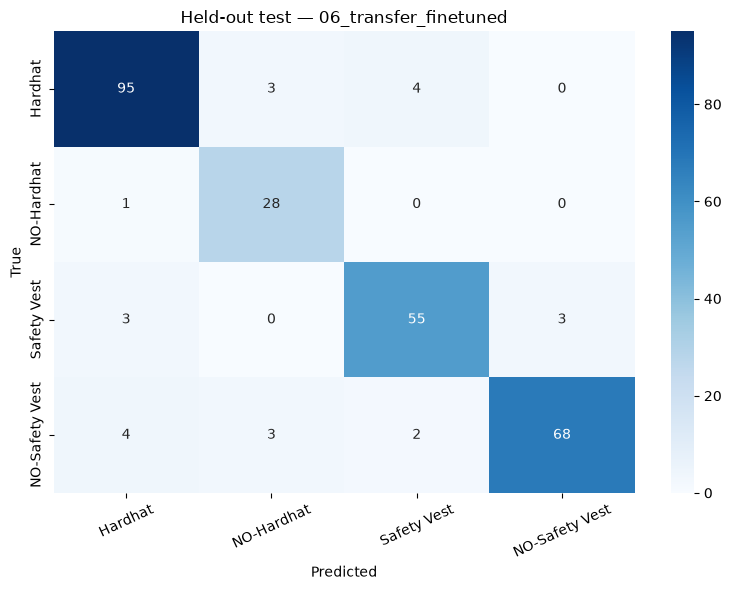

In [17]:
# Load the best checkpoint of the chosen model and score it ONCE on the held-out test set
chosen = str(VAL.iloc[0]['model'])
final_model = keras.models.load_model(CKPT / f'{chosen}.keras')
y_true = DF[DF.split == 'test'].label.to_numpy()
proba = final_model.predict(test_ds, verbose=0)
y_pred = proba.argmax(1)

report = classification_report(y_true, y_pred, labels=list(range(4)), target_names=TARGET,
                               zero_division=0, output_dict=True)
metrics = {'chosen_model': chosen,
           'test_accuracy': float(np.mean(y_true == y_pred)),
           'test_macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
           'test_balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
           'test_unsafe_recall': float(np.mean([np.mean(y_pred[y_true == i] == i) for i in (1, 3)])),
           'number_test_crops': int(len(y_true))}
(TABLES / 'final_metrics.json').write_text(json.dumps(metrics, indent=2))
(TABLES / 'classification_report.json').write_text(json.dumps(report, indent=2))
print(json.dumps(metrics, indent=2))
display(pd.DataFrame(report).T.round(3))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=TARGET, yticklabels=TARGET)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=25)
plt.title('Held-out test — ' + chosen)
plt.tight_layout()
plt.savefig(FIGS / 'test_confusion_matrix.png', dpi=180)
plt.show()

**Observations**
- **Test accuracy 0.914, macro-F1 0.909, balanced accuracy 0.920, unsafe recall 0.924** on 269 crops (23 errors). These are slightly *higher* than the validation scores (0.898 and 0.896), which suggests that model selection did not over-fit the validation set.
- **NO-Hardhat:** 28 of 29 found (recall 0.966), but precision is only 0.824, because 6 crops from other classes were labelled NO-Hardhat. For a safety screening tool, false alarms are the more acceptable kind of error.
- **NO-Safety Vest:** precision 0.958 and recall 0.883; 9 of 77 were missed, 4 of them predicted as Hardhat. This is the model's most important weakness.
- **Hardhat ↔ Safety Vest** is the most common confusion (4 + 3 = 7 crops). Both are usually bright yellow or orange, so colour alone is ambiguous.
- NO-Hardhat is never confused with Safety Vest, which makes sense: one is a head region, the other a torso region.

<a id="section-7-3"></a>

### 7.3 Learning curves

Models were loaded, not trained: showing the curves saved by the training run.


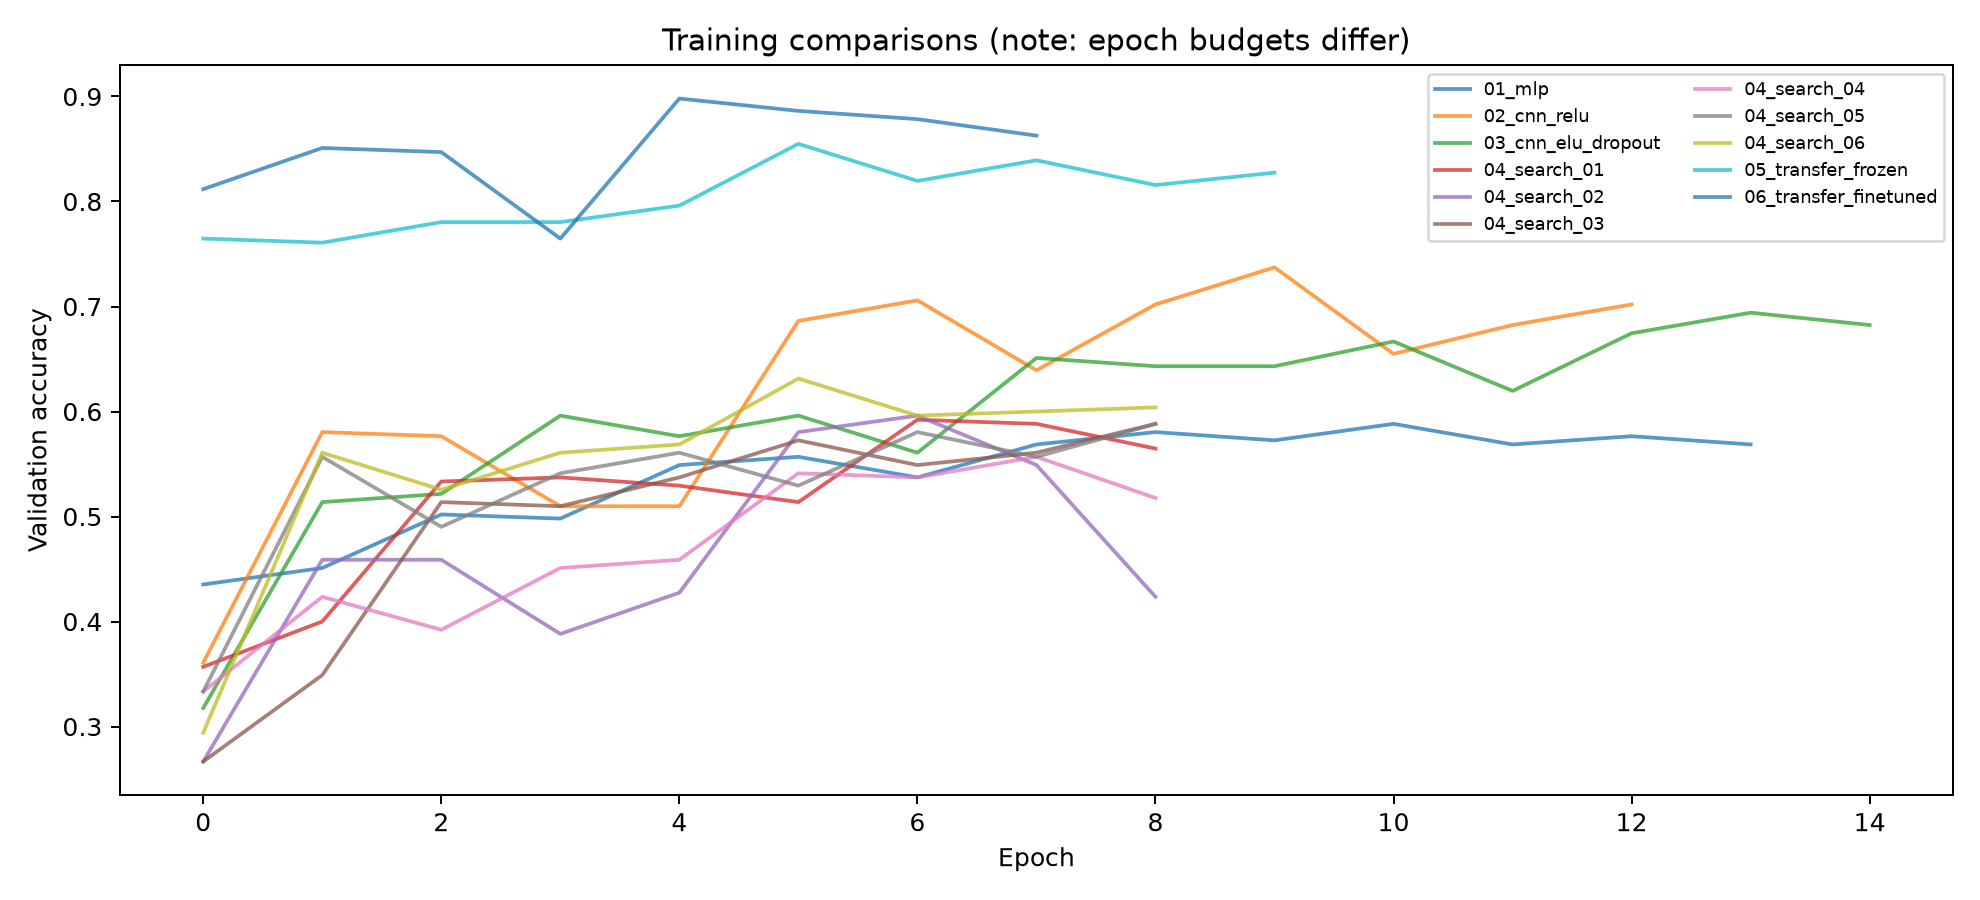

In [18]:
# Validation accuracy per epoch for every experiment (epoch budgets differ between stages)
from IPython.display import Image as ShowImage
if histories:
    fig, ax = plt.subplots(figsize=(11, 5))
    for name, h in histories.items():
        ax.plot(h['val_accuracy'], label=name, alpha=.75)
    ax.legend(fontsize=7, ncol=2)
    ax.set(xlabel='Epoch', ylabel='Validation accuracy', title='Training comparisons (note: epoch budgets differ)')
    fig.tight_layout()
    fig.savefig(FIGS / 'validation_curves.png', dpi=180)
    plt.show()
elif (FIGS / 'validation_curves.png').exists():
    print('Models were loaded, not trained: showing the curves saved by the training run.')
    display(ShowImage(filename=str(FIGS / 'validation_curves.png')))
else:
    print('No training histories available; set RETRAIN = True to produce learning curves.')

In [19]:
# Training vs validation loss for the main models: a widening gap signals over-fitting
key_models = [n for n in ['01_mlp', '02_cnn_relu', '03_cnn_elu_dropout', BEST_NAME,
                          '05_transfer_frozen', '06_transfer_finetuned'] if n in histories]
if not key_models:
    print('No saved training histories (the saved run predates history logging). '
          'Set RETRAIN = True once to record them; later loaded runs will then show these curves.')
else:
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, name in zip(axes.ravel(), key_models):
        ax.axis('on')
        h = histories[name]
        epochs = np.arange(1, len(h['loss']) + 1)
        ax.plot(epochs, h['loss'], marker='o', label='train loss')
        ax.plot(epochs, h['val_loss'], marker='o', label='validation loss')
        ax.set_title(name)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.grid(alpha=.3)
    axes.ravel()[0].legend()
    fig.suptitle('Training vs validation loss (training loss includes dropout, augmentation and L2)')
    fig.tight_layout()
    fig.savefig(FIGS / 'loss_curves.png', dpi=170)
    plt.show()

No saved training histories (the saved run predates history logging). Set RETRAIN = True once to record them; later loaded runs will then show these curves.


**Observations**
- The transfer-learning curves (at the top of the chart; `01_mlp` and `06_transfer_finetuned` share a colour) start roughly where the scratch models finish, so pretraining saves most of the training effort.
- The scratch models' curves are noisy and still rising when their epoch budgets run out, especially the 9-epoch search trials. This supports the under-training explanation in section 4.
- The fine-tuned model's dip at epoch 4 and its later decline reflect the instability and over-fitting described in 5.2.

<a id="section-7-4"></a>

### 7.4 Error analysis

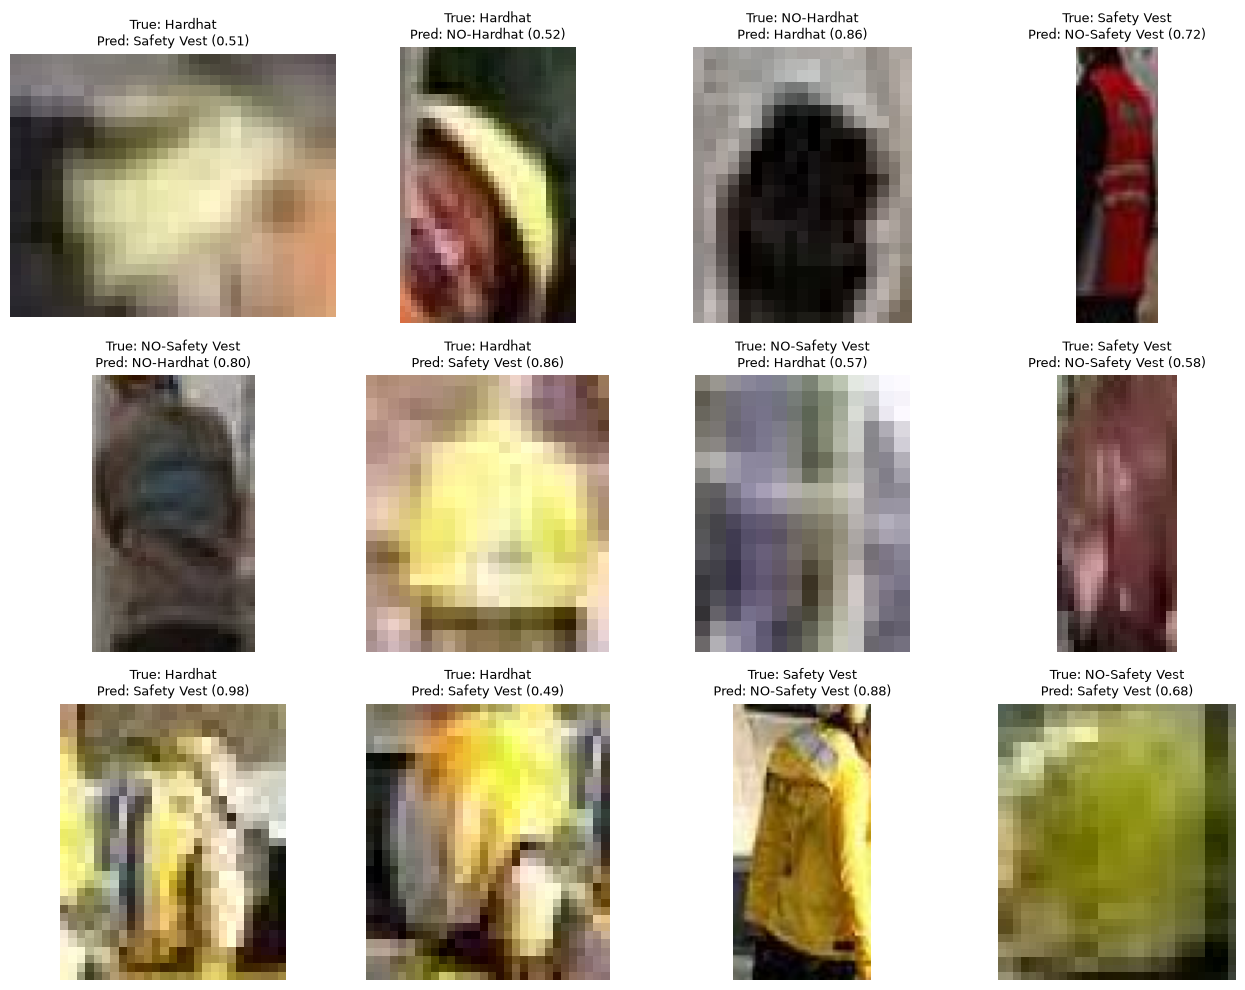

In [20]:
# Error gallery: up to 12 misclassified test crops with the model's confidence
test_rows = DF[DF.split == 'test'].reset_index(drop=True)
wrong = np.flatnonzero(y_true != y_pred)
examples = wrong[:12] if len(wrong) else np.arange(min(8, len(test_rows)))
fig, axs = plt.subplots(3, 4, figsize=(13, 10))
axs = np.ravel(axs)
for ax in axs:
    ax.axis('off')
for ax, idx in zip(axs, examples):
    r = test_rows.iloc[idx]
    im = cv2.imread(r.path)
    crop = cv2.cvtColor(im[r.y1:r.y2, r.x1:r.x2], cv2.COLOR_BGR2RGB)
    ax.imshow(crop)
    ax.set_title(f'True: {TARGET[y_true[idx]]}\nPred: {TARGET[y_pred[idx]]} ({proba[idx].max():.2f})', fontsize=9)
    ax.axis('off')
fig.tight_layout()
fig.savefig(FIGS / 'error_gallery.png', dpi=170)
plt.show()

# Export the final model and per-crop test predictions
final_model.save(MODELS / 'final_ppe_classifier.keras')
pd.DataFrame({'true': y_true, 'pred': y_pred, 'confidence': proba.max(axis=1),
              'parent_image': test_rows.parent.values}).to_csv(TABLES / 'test_predictions.csv', index=False)

**Observations**
- Most errors are **tiny, blurry crops**, only a few dozen pixels wide before enlargement, in which a yellow hard hat and a yellow vest look like the same patch of colour. This matches the smaller test crops found in 2.2.
- Several errors have **low confidence** (0.49–0.58), so a confidence threshold could send uncertain crops to a human reviewer.
- Some labels look **ambiguous or wrong**, such as a "Hardhat" crop that mostly shows a vest, so part of the remaining error may come from the annotations rather than the model.

<a id="section-7-5"></a>

### 7.5 Challenges and solutions

| Challenge | What was done | Possible further step |
|---|---|---|
| CPU-only training (6.8 hours in total) | Moderate image size (160 × 160), a lightweight backbone, early stopping | Train on a GPU (e.g. Colab) to allow larger budgets |
| Small validation and test sets (255 and 269 crops) | Macro-F1 and balanced accuracy; a single test evaluation | Cross-validation grouped by parent image, or more labelled images |
| Class imbalance (about 1.9× in training) | Inverse-frequency class weights | Focal loss or oversampling |
| Risk of leakage from the augmented export | Image-level splits, crops kept within their split, SHA-256 check | Perceptual hashing, or the unaugmented dataset version |
| Small, under-trained hyperparameter search | Limitations analysed in section 4 | Tune the number of epochs, run more trials, use Keras Tuner / Hyperband |
| Unstable fine-tuning | Low learning rate, ReduceLROnPlateau, checkpointing | Gradual unfreezing, cosine learning-rate schedule |
| Hard hat vs vest confusion on tiny crops | 10% padding for context | Higher input resolution; a minimum crop size at inference |

<a id="section-8"></a>

## ✅ 8. Conclusion
<sub>[⬆ Back to contents](#contents)</sub>

**Answer to the research question: yes.** An ImageNet-pretrained MobileNetV2 classifies PPE regions far more reliably than a dense network or a CNN trained from scratch, and it is also the strongest model on the unsafe classes.

| Stage | Best model | Val. macro-F1 | Change |
|---|---|---:|---:|
| Baseline | MLP | 0.568 | — |
| Step-by-step architecture | CNN (ReLU) | 0.696 | +0.128 |
| Hyperparameter search | `04_search_06` | 0.629 | no improvement (section 4) |
| Transfer learning, frozen | MobileNetV2 | 0.849 | +0.153 |
| Transfer learning, fine-tuned | MobileNetV2 | **0.896** | +0.047 |
| **Held-out test** | **Fine-tuned MobileNetV2** | **0.909** | accuracy 0.914, unsafe recall 0.924 |

**Key takeaways**
1. **Convolutions** gave the largest architectural gain over the MLP; changing the activation and regularization mattered far less.
2. **Transfer learning** was the single biggest improvement. Fine-tuning added more, but only with a low learning rate and checkpointing.
3. **The random search did not help** within its budget. The evidence points to too few epochs and trials rather than to the method itself.

**Threats to validity.** Version 27 contains augmented images, so near-duplicate scenes across splits cannot be ruled out completely. The evaluation sets are small, and crops from the same image are correlated. Some classes are visually ambiguous and some labels are noisy. No detection metric (mAP) or per-worker assessment was made, and no claim is made about real-world safety without field validation.

**Future work.** Re-run the hyperparameter search on a GPU with tuned epochs and batch sizes; train a YOLO detector on the unaugmented version 30 and compare per-class mAP@50–95; associate PPE with individual workers; test on images from a different construction site; calibrate the confidence scores; and keep a human in the loop.

<a id="references"></a>

## 📚 References
<sub>[⬆ Back to contents](#contents)</sub>

- **MLAI 504 course lectures:** 01 Introduction to Machine Learning and Deep Learning; 02 Neural Networks (part 1: introduction, part 2: perceptron); 03 MLP; 04 Cost and Optimization; 05 Transfer Learning; 06 CNN; 07 RNN (discussed but not applied).
- Roboflow Universe Projects, *Construction Site Safety*, dataset version 27, CC BY 4.0. https://universe.roboflow.com/roboflow-universe-projects/construction-site-safety/dataset/27
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted Residuals and Linear Bottlenecks. *CVPR*.
- Howard, A. et al. (2017). MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications. arXiv:1704.04861.
- Simonyan, K., & Zisserman, A. (2015). Very Deep Convolutional Networks for Large-Scale Image Recognition. *ICLR*.
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep Residual Learning for Image Recognition. *CVPR*.
- Bergstra, J., & Bengio, Y. (2012). Random Search for Hyper-Parameter Optimization. *JMLR*, 13.
- Kingma, D. P., & Ba, J. (2015). Adam: A Method for Stochastic Optimization. *ICLR*.
- Srivastava, N. et al. (2014). Dropout: A Simple Way to Prevent Neural Networks from Overfitting. *JMLR*, 15.
- Ioffe, S., & Szegedy, C. (2015). Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift. *ICML*.
- Clevert, D.-A., Unterthiner, T., & Hochreiter, S. (2016). Fast and Accurate Deep Network Learning by Exponential Linear Units (ELUs). *ICLR*.
- TensorFlow / Keras documentation: https://www.tensorflow.org/api_docs/python/tf/keras
- scikit-learn, classification metrics: https://scikit-learn.org/stable/modules/model_evaluation.html